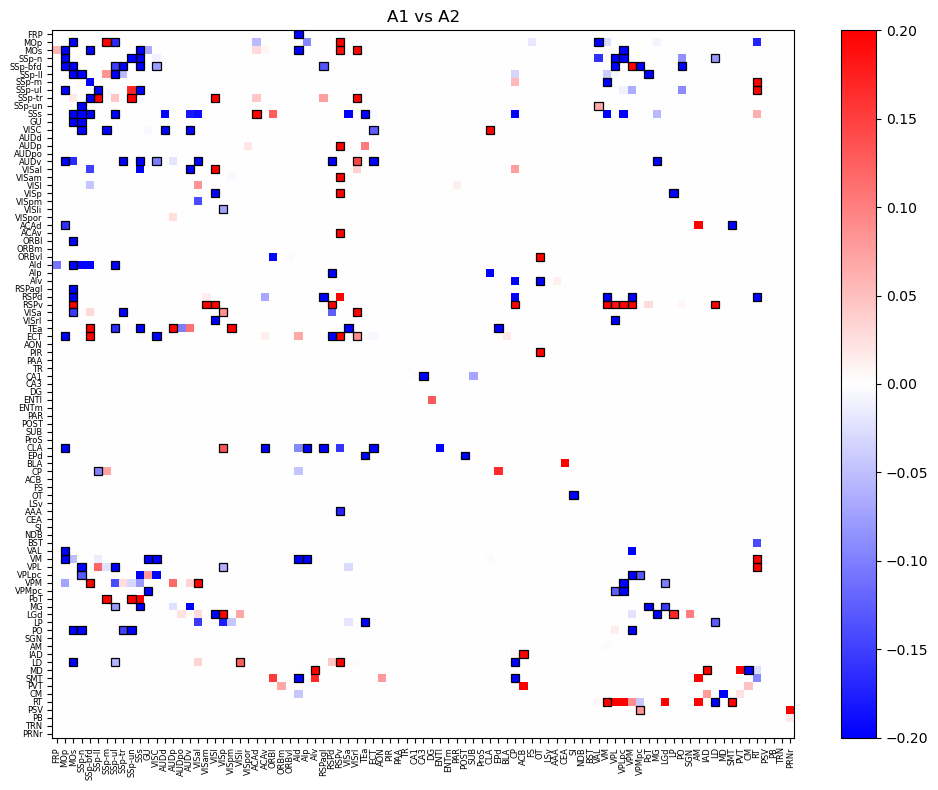

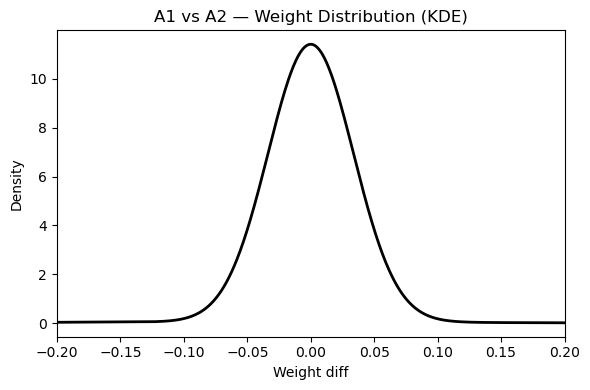

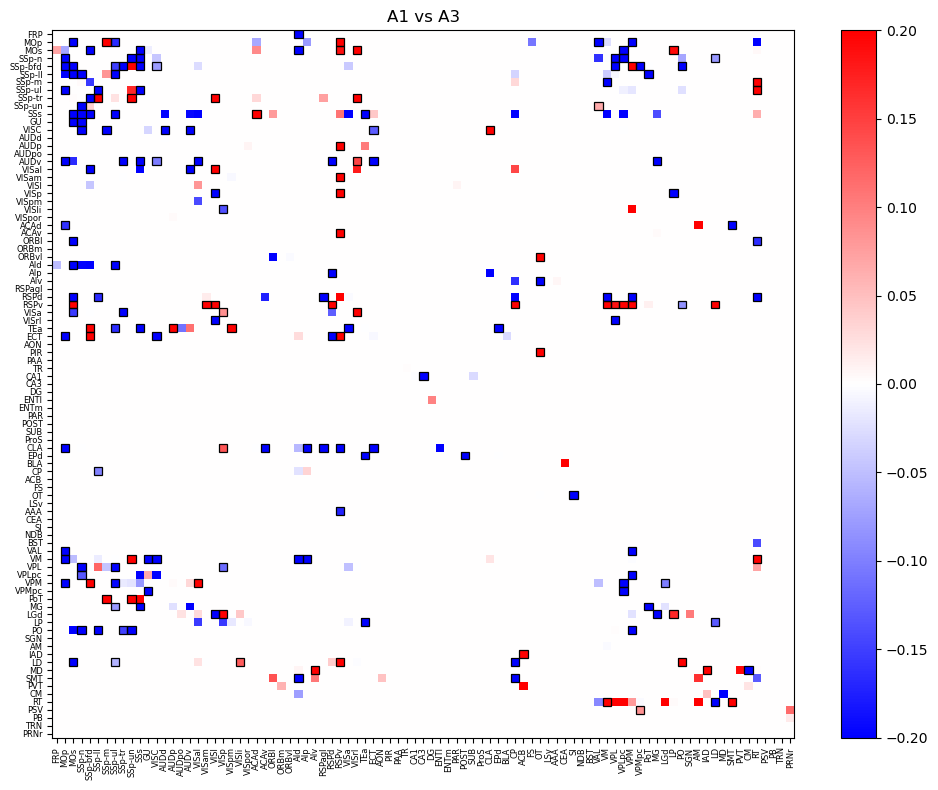

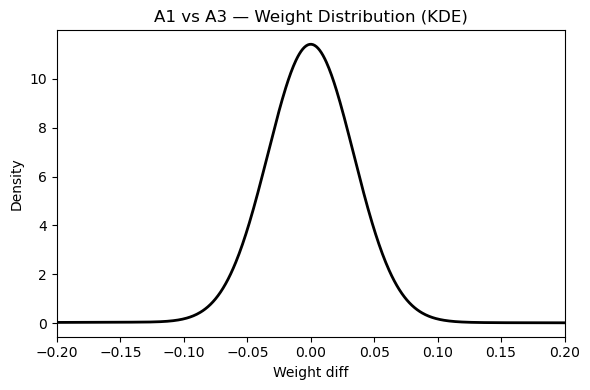

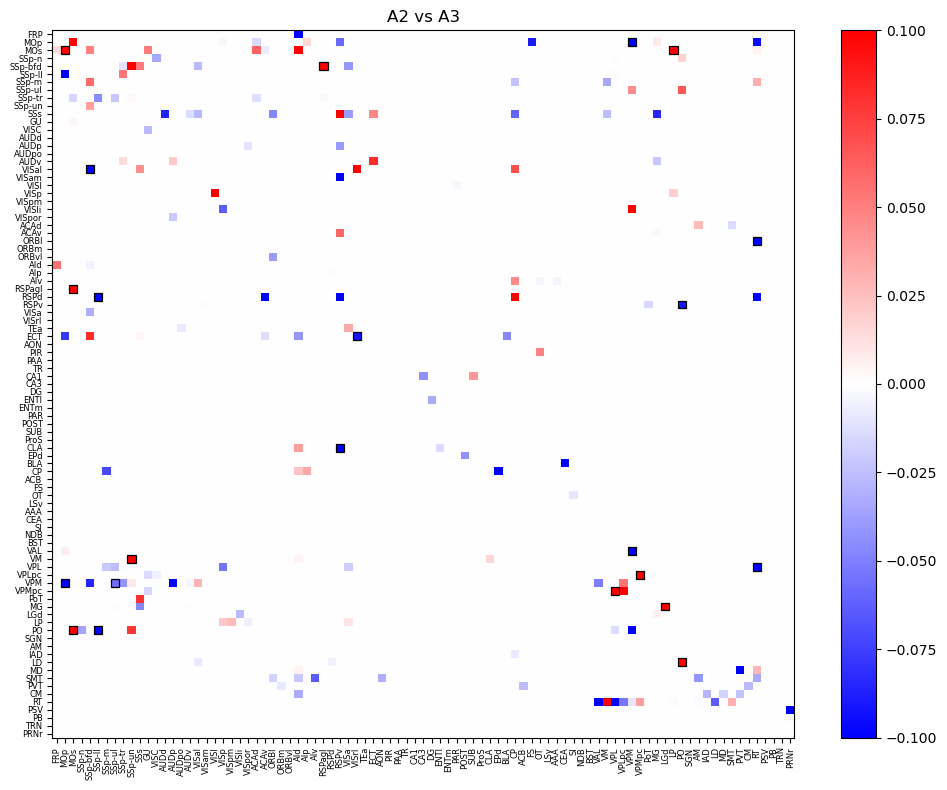

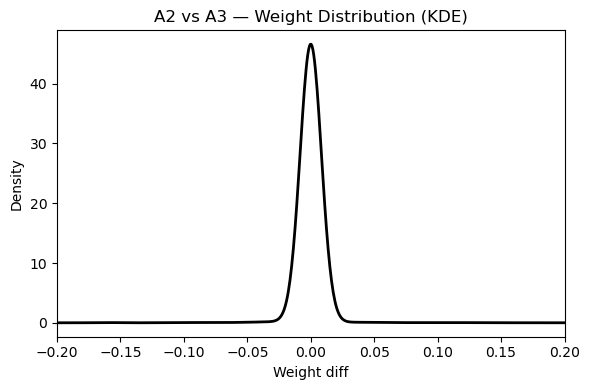

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from scipy.stats import gaussian_kde


def load_mean_adj(graph_path, label_path):
    graphs = np.load(graph_path)
    adj = graphs.mean(axis=0)
    df = pd.read_csv(label_path)
    labels = df.iloc[:, 0].astype(str).str.strip().values
    return adj, labels


def plot_heatmap_only(adj1, adj2, diff_mat, labels, title,
                      vmin=None, vmax=None, savepdf=None):

    n = diff_mat.shape[0]
    if vmin is None:
        vmin = diff_mat.min()
    if vmax is None:
        vmax = diff_mat.max()

    fig = plt.figure(figsize=(10, 8))
    x = np.arange(n + 1)
    y = np.arange(n + 1)

    plt.pcolormesh(
        x, y, diff_mat,
        cmap='bwr',
        vmin=vmin, vmax=vmax,
        shading='flat'
    )
    plt.colorbar()
    plt.title(title)

    plt.xticks(np.arange(n) + 0.5, labels, rotation=90, fontsize=6)
    plt.yticks(np.arange(n) + 0.5, labels, fontsize=6)

    opposite = (adj1 * adj2) < 0
    ax = plt.gca()
    for i in range(n):
        for j in range(n):
            if opposite[i, j]:
                ax.add_patch(
                    patches.Rectangle(
                        (j, i), 1, 1,
                        linewidth=0.9,
                        edgecolor="black",
                        facecolor="none"
                    )
                )

    plt.gca().invert_yaxis()
    plt.tight_layout()

    if savepdf is not None:
        fig.savefig(savepdf, format="pdf", dpi=300, bbox_inches="tight")

    plt.show()


def plot_kde_only(diff_mat, title, dist_xlim=None, kde_bw=0.3, savepdf=None):

    diff_vals = diff_mat.flatten()
    kde = gaussian_kde(diff_vals, bw_method=kde_bw)

    if dist_xlim is None:
        xmin, xmax = diff_vals.min(), diff_vals.max()
    else:
        xmin, xmax = dist_xlim

    xs = np.linspace(xmin, xmax, 600)
    ys = kde(xs)

    fig = plt.figure(figsize=(6, 4))
    plt.plot(xs, ys, color="black", linewidth=2)
    plt.title(f"{title} — Weight Distribution (KDE)")
    plt.xlabel("Weight diff")
    plt.ylabel("Density")

    if dist_xlim is not None:
        plt.xlim(dist_xlim)

    plt.tight_layout()

    if savepdf is not None:
        fig.savefig(savepdf, format="pdf", dpi=300, bbox_inches="tight")

    plt.show()



A1, L1 = load_mean_adj(
    './result/wo_layer/stage1/tuning/bs8_dp0.1_sw1.0/dynamic_full_graphs.npy',
    './result/wo_layer/stage1/df_scaled.csv'
)

A2, L2 = load_mean_adj(
    './result/wo_layer/stage2/tuning/bs64_dp0.8_sw0.7/dynamic_full_graphs.npy',
    './result/wo_layer/stage2/df_scaled.csv'
)

A3, L3 = load_mean_adj(
    './result/wo_layer/stage3/tuning/bs64_dp0.8_sw1.0/dynamic_full_graphs.npy',
    './result/wo_layer/stage3/df_scaled.csv'
)

D12 = A1 - A2
D13 = A1 - A3
D23 = A2 - A3


plot_heatmap_only(
    A1, A2, D12, L1,
    "A1 vs A2",
    vmin=-0.2, vmax=0.2,
    savepdf="./result/fig/A1_vs_A2_heatmap.pdf"
)
plot_kde_only(
    D12, "A1 vs A2",
    dist_xlim=(-0.2, 0.2),
    savepdf="./result/fig/A1_vs_A2_KDE.pdf"
)


plot_heatmap_only(
    A1, A3, D13, L1,
    "A1 vs A3",
    vmin=-0.2, vmax=0.2,
    savepdf="./result/fig/A1_vs_A3_heatmap.pdf"
)
plot_kde_only(
    D13, "A1 vs A3",
    dist_xlim=(-0.2, 0.2),
    savepdf="./result/fig/A1_vs_A3_KDE.pdf"
)


plot_heatmap_only(
    A2, A3, D23, L2,
    "A2 vs A3",
    vmin=-0.1, vmax=0.1,
    savepdf="./result/fig/A2_vs_A3_heatmap.pdf"
)
plot_kde_only(
    D23, "A2 vs A3",
    dist_xlim=(-0.2, 0.2),
    savepdf="./result/fig/A2_vs_A3_KDE.pdf"
)


In [2]:
import numpy as np
import pandas as pd
import networkx as nx


# =======================
# --- 构建图：忽略权重为 0 的边 ---
# =======================
def build_graph_from_adj(A):
    G = nx.Graph()
    n = A.shape[0]
    for i in range(n):
        for j in range(i+1, n):
            if A[i, j] != 0:
                G.add_edge(i, j, weight=float(A[i, j]))
    return G


# =======================
# --- 中心性差值（不会报错） ---
# =======================
def centrality_diff(Aa, Ab):
    G1 = build_graph_from_adj(Aa)
    G2 = build_graph_from_adj(Ab)

    n = Aa.shape[0]

    bc1 = nx.betweenness_centrality(G1, weight="weight")
    bc2 = nx.betweenness_centrality(G2, weight="weight")

    diff = np.zeros(n)
    for i in range(n):
        diff[i] = bc1.get(i, 0.0) - bc2.get(i, 0.0)

    return diff


# =======================
# --- 主函数：变化枢纽 ---
# =======================
def compute_change_hubs(A1, A2, A3, labels):

    n = A1.shape[0]

    # 差值矩阵
    D12 = A1 - A2
    D13 = A1 - A3
    D23 = A2 - A3

    # 1️⃣ NodeChangeScore（整体变化强度）
    NodeChange_12 = np.sum(np.abs(D12), axis=1)
    NodeChange_13 = np.sum(np.abs(D13), axis=1)
    NodeChange_23 = np.sum(np.abs(D23), axis=1)

    # 2️⃣ Significant edges（显著变化）
    th12 = np.percentile(np.abs(D12), 95)
    th13 = np.percentile(np.abs(D13), 95)
    th23 = np.percentile(np.abs(D23), 95)

    SigEdges_12 = np.sum(np.abs(D12) > th12, axis=1)
    SigEdges_13 = np.sum(np.abs(D13) > th13, axis=1)
    SigEdges_23 = np.sum(np.abs(D23) > th23, axis=1)

    # 3️⃣ 中心性差值（修复后不会报错）
    BC_12 = centrality_diff(A1, A2)
    BC_13 = centrality_diff(A1, A3)
    BC_23 = centrality_diff(A2, A3)

    # 归一化函数
    def normalize(x):
        return (x - x.min()) / (x.max() - x.min() + 1e-9)

    # 4️⃣ 综合枢纽评分
    Hub_12 = 0.5 * normalize(NodeChange_12) + \
             0.3 * normalize(SigEdges_12) + \
             0.2 * normalize(np.abs(BC_12))

    Hub_13 = 0.5 * normalize(NodeChange_13) + \
             0.3 * normalize(SigEdges_13) + \
             0.2 * normalize(np.abs(BC_13))

    Hub_23 = 0.5 * normalize(NodeChange_23) + \
             0.3 * normalize(SigEdges_23) + \
             0.2 * normalize(np.abs(BC_23))

    # 5️⃣ 输出表格
    df = pd.DataFrame({
        "Region": labels,
        "NodeChange_12": NodeChange_12,
        "NodeChange_13": NodeChange_13,
        "NodeChange_23": NodeChange_23,
        "SigEdges_12": SigEdges_12,
        "SigEdges_13": SigEdges_13,
        "SigEdges_23": SigEdges_23,
        "BC_Δ12": BC_12,
        "BC_Δ13": BC_13,
        "BC_Δ23": BC_23,
        "HubScore_12": Hub_12,
        "HubScore_13": Hub_13,
        "HubScore_23": Hub_23
    })

    return df.sort_values("HubScore_12", ascending=False)


In [3]:
df_hub = compute_change_hubs(A1, A2, A3, L1)
df_hub.head(10)

,Region,NodeChange_12,NodeChange_13,NodeChange_23,SigEdges_12,SigEdges_13,SigEdges_23,BC_Δ12,BC_Δ13,BC_Δ23,HubScore_12,HubScore_13,HubScore_23
34,RSPv,6.926831,6.989349,0.107610,13,12,4,-0.124148,-0.147517,-0.023369,0.741078,0.731171,0.149182
10,SSs,5.497948,5.935923,0.541221,19,19,12,0.026452,-0.001623,-0.028075,0.704490,0.725099,0.474826
66,VM,3.798287,4.038816,0.249192,11,12,3,0.693281,0.707562,0.014281,0.647856,0.678400,0.156593
16,AUDv,4.706514,4.609901,0.139464,11,10,4,0.410419,0.417235,0.006816,0.631814,0.605611,0.144710
52,CLA,5.099046,5.520131,0.495340,12,11,4,-0.212431,-0.381694,-0.169263,0.618821,0.676470,0.376409
4,SSp-bfd,5.284404,5.470954,0.557360,12,14,6,-0.114086,-0.094612,0.019474,0.603830,0.639174,0.322387
2,MOs,5.063902,4.603399,1.008317,12,12,10,0.156767,0.080656,-0.076112,0.600226,0.541587,0.595010
73,LGd,3.199166,3.167566,0.034343,10,10,3,-0.566537,-0.538786,0.027751,0.552257,0.536788,0.107149
84,RT,4.355936,4.326801,0.650043,11,11,11,0.208536,0.166342,-0.042194,0.548268,0.530231,0.491848
37,TEa,3.485431,3.459571,0.041817,10,10,4,0.376663,0.353944,-0.022720,0.518145,0.505429,0.130170


In [13]:
df_hub.sort_values("HubScore_12", ascending=False)[['Region', 'HubScore_12']] \
      .to_csv("HubScore_12_sorted.csv", index=False)

df_hub.sort_values("HubScore_13", ascending=False)[['Region', 'HubScore_13']] \
      .to_csv("HubScore_13_sorted.csv", index=False)

df_hub.sort_values("HubScore_23", ascending=False)[['Region', 'HubScore_23']] \
      .to_csv("HubScore_23_sorted.csv", index=False)

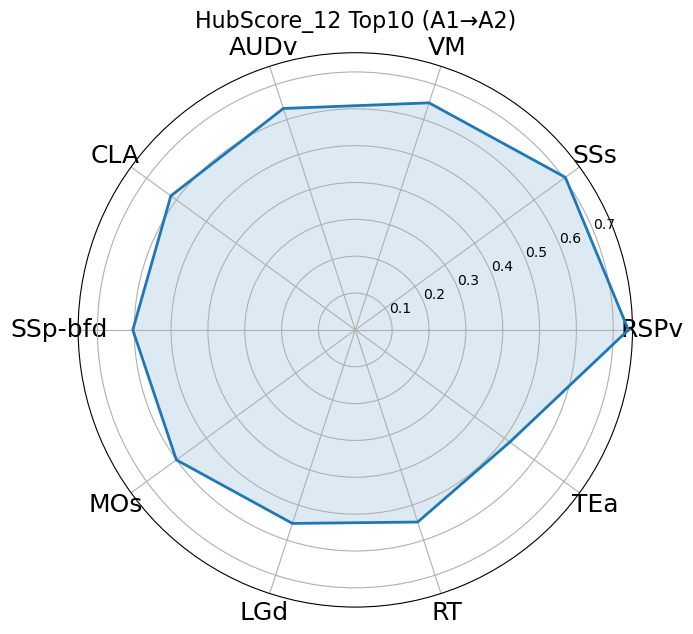

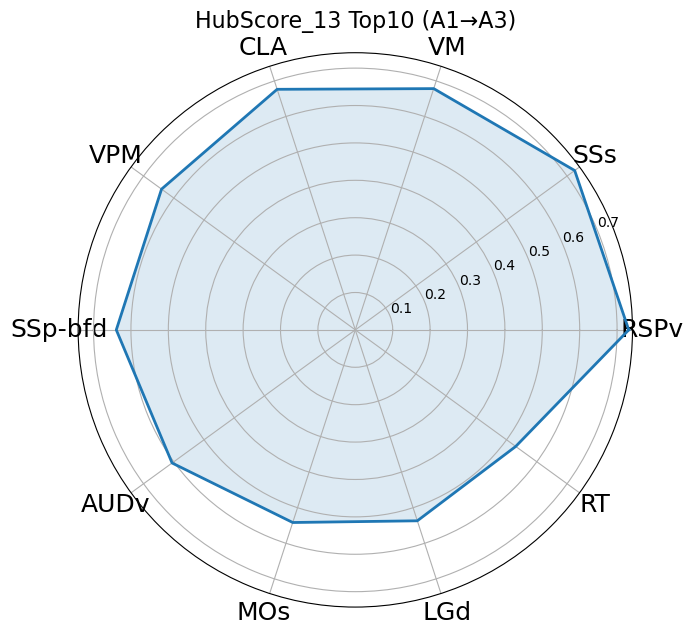

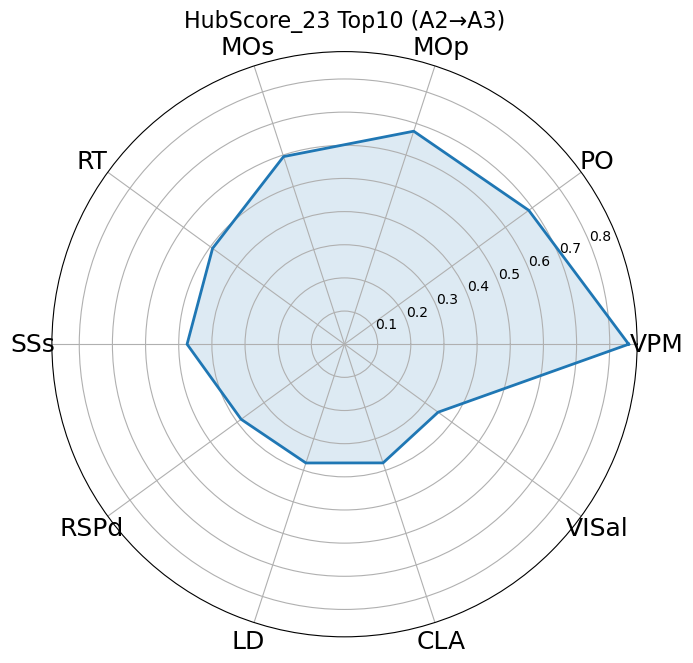

In [129]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def draw_radar_single(regions, values, title, fontsize_labels=12, savepdf=None):
    N = len(regions)
    angles = np.linspace(0, 2*np.pi, N, endpoint=False).tolist()
    angles += angles[:1]
    v = np.concatenate([values, [values[0]]])

    fig, ax = plt.subplots(figsize=(7, 7), subplot_kw={'polar': True})

    ax.plot(angles, v, linewidth=2)
    ax.fill(angles, v, alpha=0.15)

    ax.set_xticks(angles[:-1])
    ax.set_xticklabels(regions, fontsize=fontsize_labels)
    ax.set_title(title, fontsize=16)
    ax.grid(True)

    plt.tight_layout()

    if savepdf is not None:
        plt.savefig(savepdf, dpi=300, format="pdf")
    plt.show()
    plt.close(fig)


def plot_radar_separate(df_hub, fontsize_labels=12, outdir="./result/fig/"):
    top12 = df_hub.sort_values("HubScore_12", ascending=False).head(10)
    top13 = df_hub.sort_values("HubScore_13", ascending=False).head(10)
    top23 = df_hub.sort_values("HubScore_23", ascending=False).head(10)

    draw_radar_single(
        top12["Region"].values,
        top12["HubScore_12"].values,
        "HubScore_12 Top10 (A1→A2)",
        fontsize_labels,
        savepdf=f"{outdir}/radar_A1_A2.pdf"
    )

    draw_radar_single(
        top13["Region"].values,
        top13["HubScore_13"].values,
        "HubScore_13 Top10 (A1→A3)",
        fontsize_labels,
        savepdf=f"{outdir}/radar_A1_A3.pdf"
    )

    draw_radar_single(
        top23["Region"].values,
        top23["HubScore_23"].values,
        "HubScore_23 Top10 (A2→A3)",
        fontsize_labels,
        savepdf=f"{outdir}/radar_A2_A3.pdf"
    )


plot_radar_separate(df_hub, fontsize_labels=18)

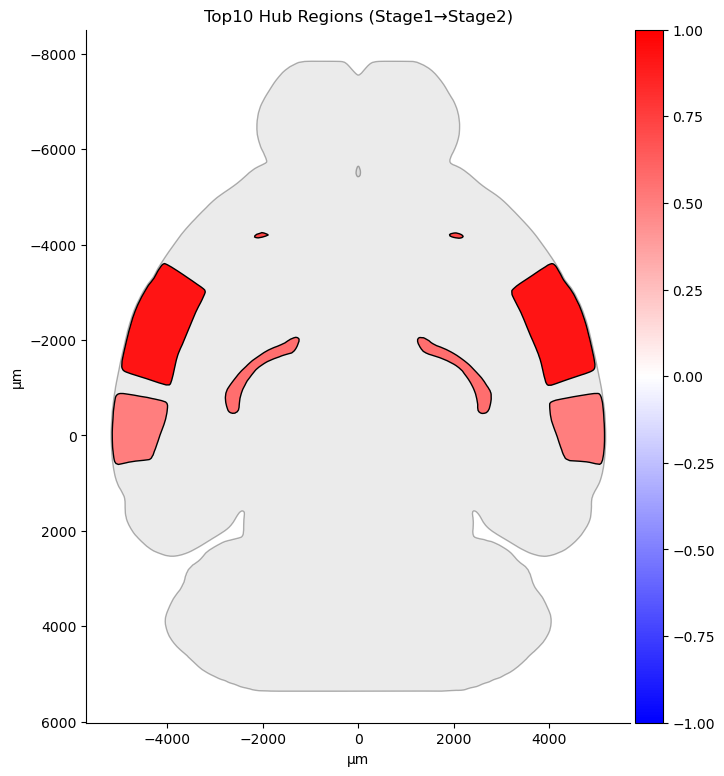

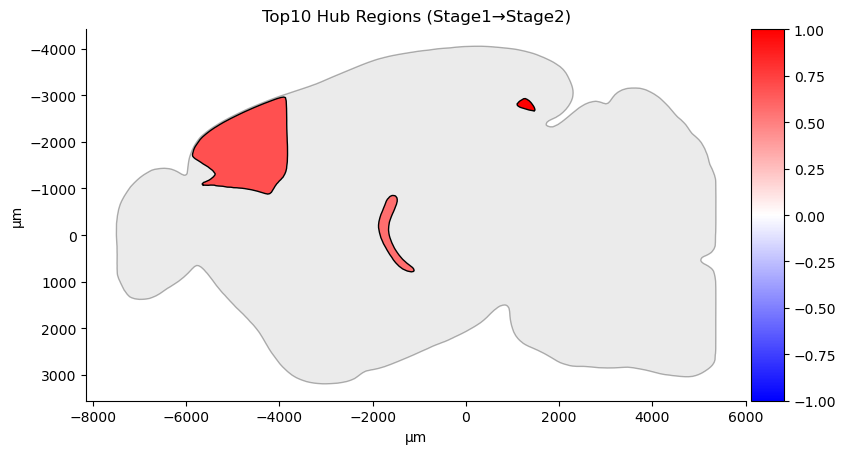

In [156]:
import numpy as np
import brainrender as br
import brainglobe_heatmap as bgh

top12 = df_hub.sort_values("HubScore_12", ascending=False).head(10)
regions = top12["Region"].values
scores = top12["HubScore_12"].values

def normalize_to_range(values, new_min=0.5, new_max=1):
    v = np.array(values)
    old_min, old_max = v.min(), v.max()
    scaled = (v - old_min) / (old_max - old_min + 1e-9)
    scaled = scaled * (new_max - new_min) + new_min
    return scaled

norm_scores = normalize_to_range(scores)
region_value_dict = dict(zip(regions, norm_scores))

fig = bgh.Heatmap(
    values=region_value_dict,
    hemisphere="all",
    position=4000,
    orientation="horizontal",
    thickness=1500,
    format="2D",
    vmin=-1,
    vmax=1,
    cmap="bwr",
    atlas_name="allen_mouse_25um",
    title="Top10 Hub Regions (Stage1→Stage2)"
).plot(size=(500, 350), axes=False)

fig = bgh.Heatmap(
    values=region_value_dict,
    hemisphere="all",
    position=4000,
    orientation="sagittal",
    thickness=1500,
    format="2D",
    vmin=-1,
    vmax=1,
    cmap="bwr",
    atlas_name="allen_mouse_25um",
    title="Top10 Hub Regions (Stage1→Stage2)"
).plot(size=(500, 350), axes=False)

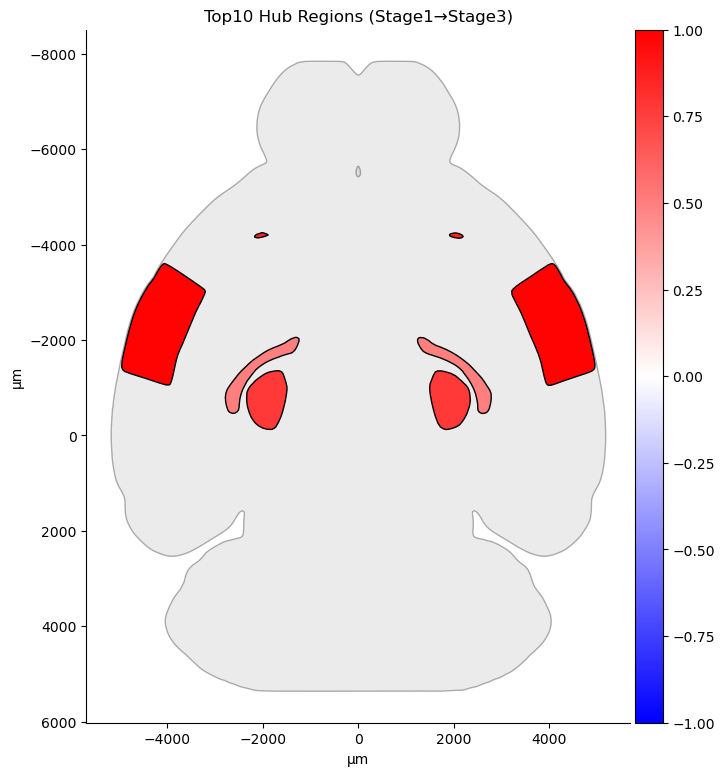

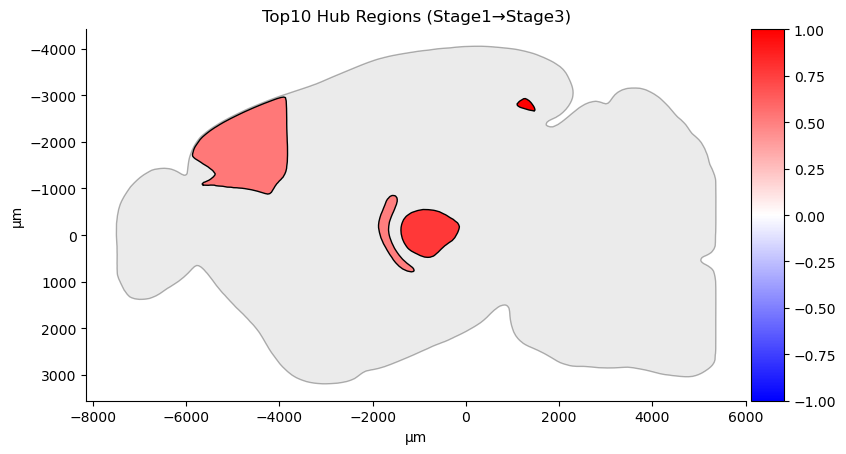

In [157]:
import numpy as np
import brainrender as br
import brainglobe_heatmap as bgh

top13 = df_hub.sort_values("HubScore_13", ascending=False).head(10)
regions = top13["Region"].values
scores = top13["HubScore_13"].values

def normalize_to_range(values, new_min=0.5, new_max=1):
    v = np.array(values)
    old_min, old_max = v.min(), v.max()
    scaled = (v - old_min) / (old_max - old_min + 1e-9)
    scaled = scaled * (new_max - new_min) + new_min
    return scaled

norm_scores = normalize_to_range(scores)
region_value_dict = dict(zip(regions, norm_scores))

fig = bgh.Heatmap(
    values=region_value_dict,
    hemisphere="all",
    position=4000,
    orientation="horizontal",
    thickness=1500,
    format="2D",
    vmin=-1,
    vmax=1,
    cmap="bwr",
    atlas_name="allen_mouse_25um",
    title="Top10 Hub Regions (Stage1→Stage3)"
).plot(size=(500, 350), axes=False)

fig = bgh.Heatmap(
    values=region_value_dict,
    hemisphere="all",
    position=4000,
    orientation="sagittal",
    thickness=1500,
    format="2D",
    vmin=-1,
    vmax=1,
    cmap="bwr",
    atlas_name="allen_mouse_25um",
    title="Top10 Hub Regions (Stage1→Stage3)"
).plot(size=(500, 350), axes=False)


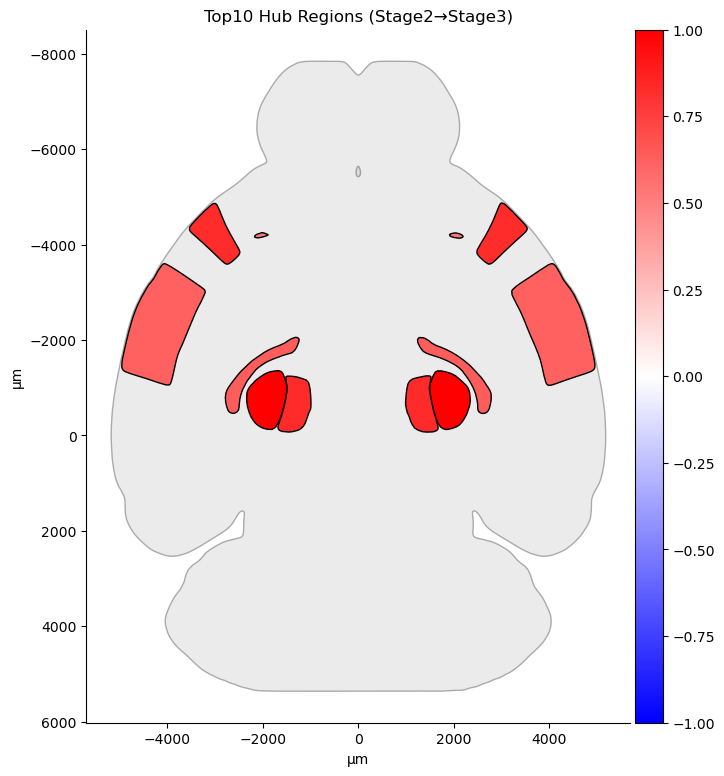

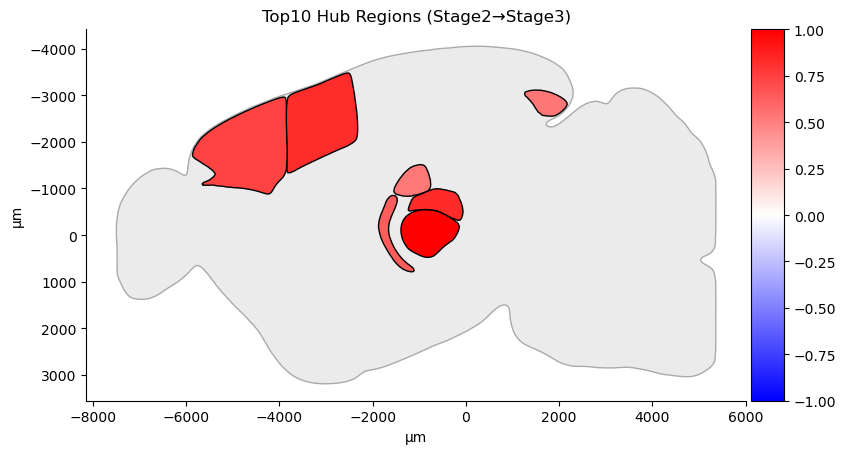

In [158]:
import numpy as np
import brainrender as br
import brainglobe_heatmap as bgh

top23 = df_hub.sort_values("HubScore_23", ascending=False).head(10)
regions = top23["Region"].values
scores = top23["HubScore_23"].values

def normalize_to_range(values, new_min=0.5, new_max=1):
    v = np.array(values)
    old_min, old_max = v.min(), v.max()
    scaled = (v - old_min) / (old_max - old_min + 1e-9)
    scaled = scaled * (new_max - new_min) + new_min
    return scaled

norm_scores = normalize_to_range(scores)
region_value_dict = dict(zip(regions, norm_scores))

fig = bgh.Heatmap(
    values=region_value_dict,
    hemisphere="all",
    position=4000,
    orientation="horizontal",
    thickness=1500,
    format="2D",
    vmin=-1,
    vmax=1,
    cmap="bwr",
    atlas_name="allen_mouse_25um",
    title="Top10 Hub Regions (Stage2→Stage3)"
).plot(size=(500, 350), axes=False)

fig = bgh.Heatmap(
    values=region_value_dict,
    hemisphere="all",
    position=4000,
    orientation="sagittal",
    thickness=1500,
    format="2D",
    vmin=-1,
    vmax=1,
    cmap="bwr",
    atlas_name="allen_mouse_25um",
    title="Top10 Hub Regions (Stage2→Stage3)"
).plot(size=(500, 350), axes=False)


In [150]:
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
import matplotlib.patheffects as path_effects
from matplotlib.colors import ListedColormap, BoundaryNorm

def adjust_labels_smart(pos, labels, ax, fontsize=9, push_strength=0.02, iterations=80):
    label_pos = {k: np.array(v, dtype=float) for k, v in pos.items()}
    renderer = ax.figure.canvas.get_renderer()
    for _ in range(iterations):
        changed = False
        items = list(label_pos.items())
        bboxes = {}
        for idx, p in items:
            t = ax.text(p[0], p[1], labels[idx], fontsize=fontsize)
            bb = t.get_window_extent(renderer).expanded(1.1, 1.1)
            bboxes[idx] = bb
            t.remove()
        for i in range(len(items)):
            idx1, p1 = items[i]
            bb1 = bboxes[idx1]
            for j in range(i + 1, len(items)):
                idx2, p2 = items[j]
                bb2 = bboxes[idx2]
                if bb1.overlaps(bb2):
                    v = p1 - p2
                    if np.linalg.norm(v) < 1e-9:
                        v = np.random.randn(2)
                    v = v / np.linalg.norm(v)
                    label_pos[idx1] += push_strength * v
                    label_pos[idx2] -= push_strength * v
                    changed = True
        if not changed:
            break
    return label_pos


def draw_label(ax, x, y, text, fontsize=9, alpha_box=0.3):
    t = ax.text(x, y, text,
                fontsize=fontsize, fontweight="bold",
                ha="center", va="center",
                bbox=dict(boxstyle="round,pad=0.25",
                          fc=(1, 1, 1, alpha_box), ec="none"))
    t.set_path_effects([path_effects.Stroke(linewidth=3, foreground="white"),
                        path_effects.Normal()])


def plot_explainable_network(diff_mat, labels, df_hub, score_col,
                             top_k=150, title="Network Explanation",
                             savepdf=None):

    labels = np.array(labels)
    df_idx = df_hub.set_index("Region")
    hub_scores = df_idx.loc[labels, score_col].values

    n = len(labels)
    G = nx.Graph()
    for i in range(n):
        G.add_node(i, label=labels[i], hub=hub_scores[i])

    edges = []
    for i in range(n):
        for j in range(i+1, n):
            v = diff_mat[i, j]
            edges.append((i, j, abs(v), v))
    edges_sorted = sorted(edges, key=lambda x: x[2], reverse=True)[:top_k]

    for i, j, a, v in edges_sorted:
        G.add_edge(i, j, weight=a, sign=np.sign(v))

    pos = nx.spring_layout(G, seed=1, k=0.3)

    fig, ax = plt.subplots(figsize=(14, 12))

    # ==========================================================
    # 1) Node colormap (continuous)
    # ==========================================================
    node_vmin = 0
    node_vmax = 0.9
    
    node_sizes = 2200 * (hub_scores - hub_scores.min()) / (hub_scores.max() - hub_scores.min() + 1e-9)
    
    node_colors = hub_scores


    nodes = nx.draw_networkx_nodes(
        G, pos, ax=ax,
        node_size=node_sizes,
        node_color=node_colors,
        cmap="Purples",
        vmin=node_vmin,
        vmax=node_vmax
    )

    # ==========================================================
    # 2) Edges and categorical edge colorbar (red / blue)
    # ==========================================================
    edge_colors = ['red' if G[u][v]['sign'] > 0 else 'blue'
                   for u, v in G.edges()]
    widths = [G[u][v]['weight'] * 5 for u, v in G.edges()]

    nx.draw_networkx_edges(
        G, pos, ax=ax,
        width=widths,
        edge_color=edge_colors,
        alpha=0.55
    )

    # --- build discrete colorbar for edges ---
    cmap_edges = ListedColormap(["blue", "red"])
    bounds = [-1, 0, 1]
    norm = BoundaryNorm(bounds, cmap_edges.N)

    #cbar_edges = fig.colorbar(
    #    plt.cm.ScalarMappable(cmap=cmap_edges, norm=norm),
    #    ax=ax, fraction=0.03, pad=0.01
    #)
    #cbar_edges.set_ticks([-0.5, 0.5])
    #cbar_edges.set_ticklabels(["Decrease", "Increase"])
    #cbar_edges.set_label("Connection Change Sign")

    # ==========================================================
    # 3) Node labels with overlap reduction
    # ==========================================================
    label_pos = adjust_labels_smart(pos, labels, ax, fontsize=9)
    for i, (lx, ly) in label_pos.items():
        draw_label(ax, lx, ly, labels[i])

    ax.set_title(title, fontsize=18)
    ax.axis("off")

    # ==========================================================
    # 4) Node colorbar
    # ==========================================================
    sm = plt.cm.ScalarMappable(cmap="Purples",norm=plt.Normalize(vmin=node_vmin, vmax=node_vmax))
    sm.set_array([])
    fig.colorbar(sm, ax=ax, label=score_col, fraction=0.03, pad=0.04)

    if savepdf is not None:
        plt.savefig(savepdf, dpi=300, format="png")
    plt.show()


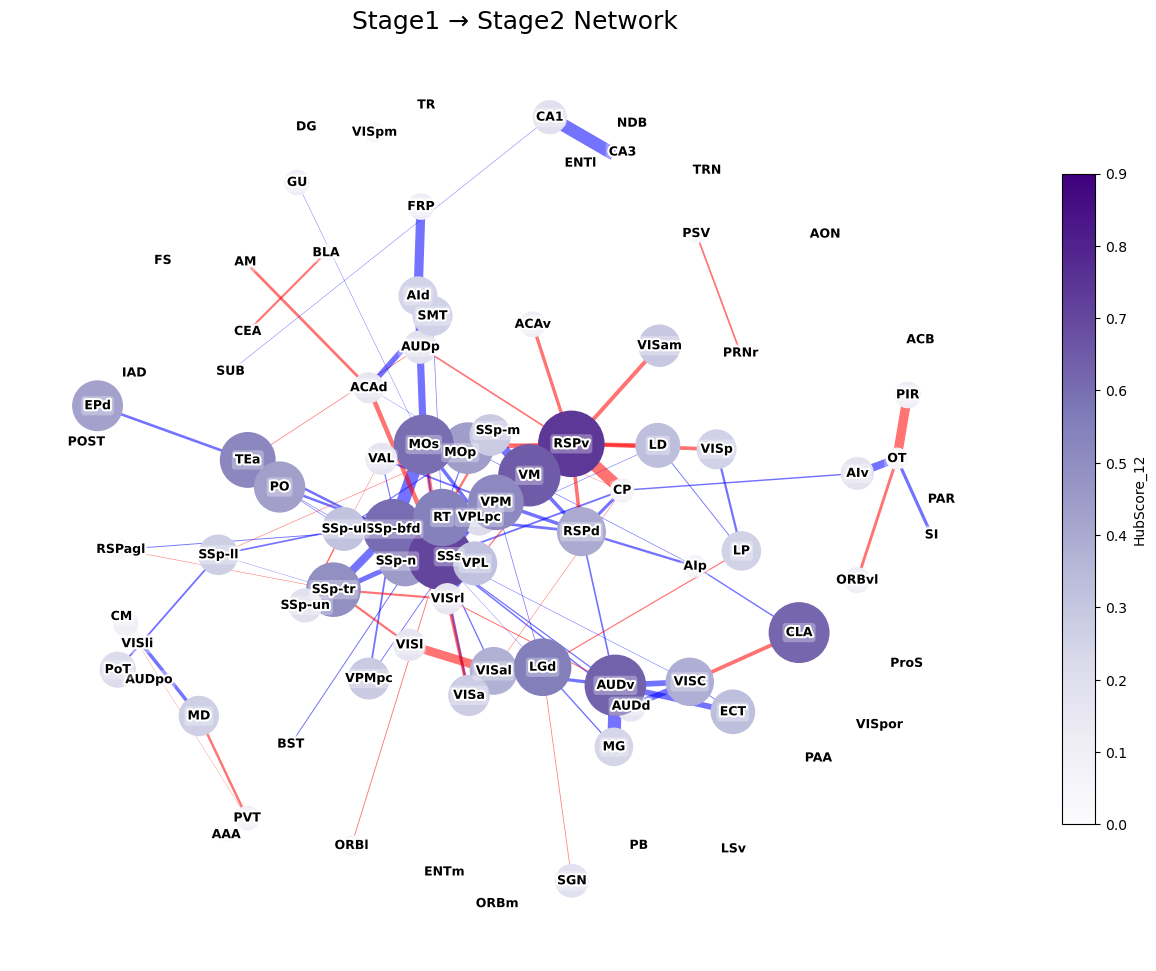

In [151]:
plot_explainable_network(
    D12, L1, df_hub, "HubScore_12",
    top_k=120,
    title="Stage1 → Stage2 Network",
    savepdf="./result/fig/network_stage12.png"
)

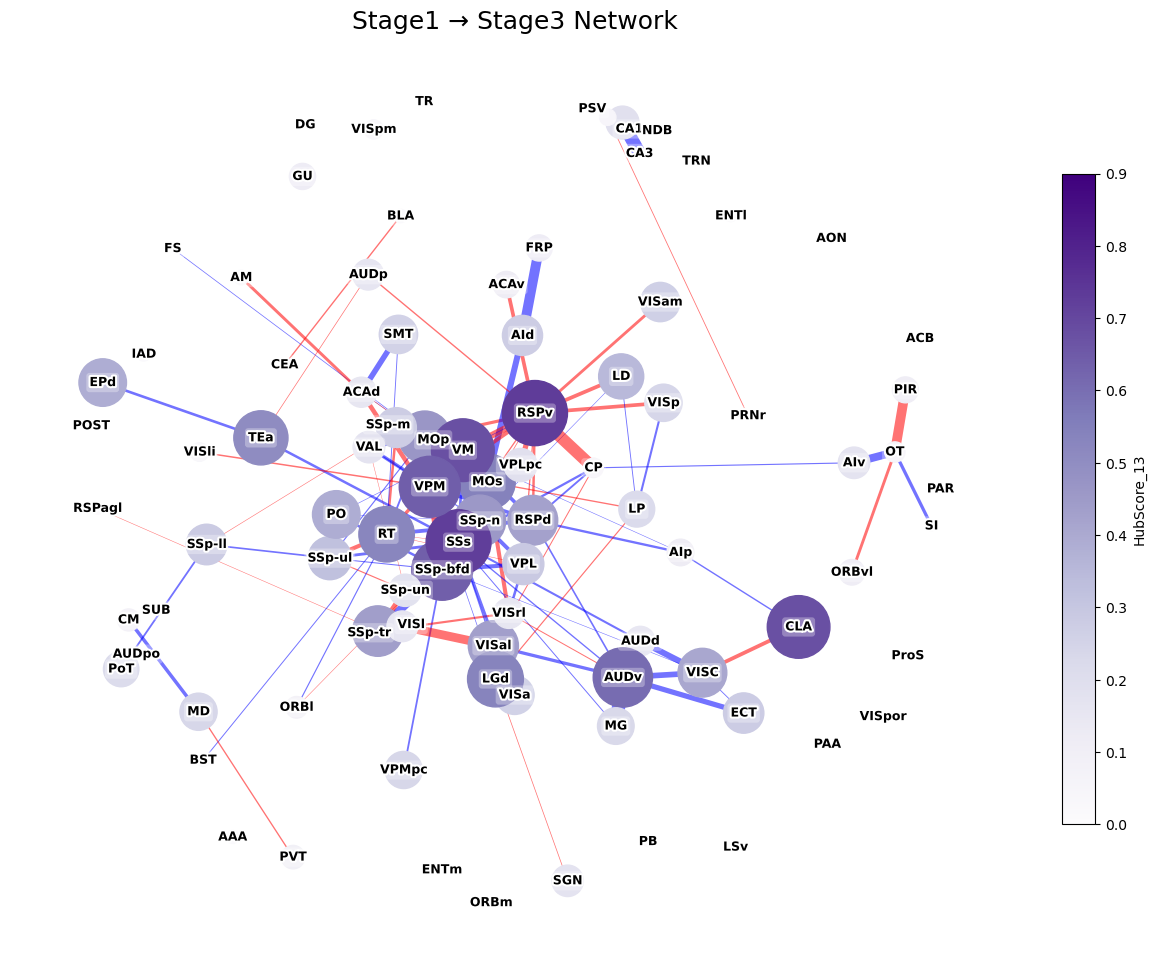

In [144]:
plot_explainable_network(
    D13, L1, df_hub, "HubScore_13",
    top_k=120,
    title="Stage1 → Stage3 Network",
    savepdf="./result/fig/network_stage13.png"
)

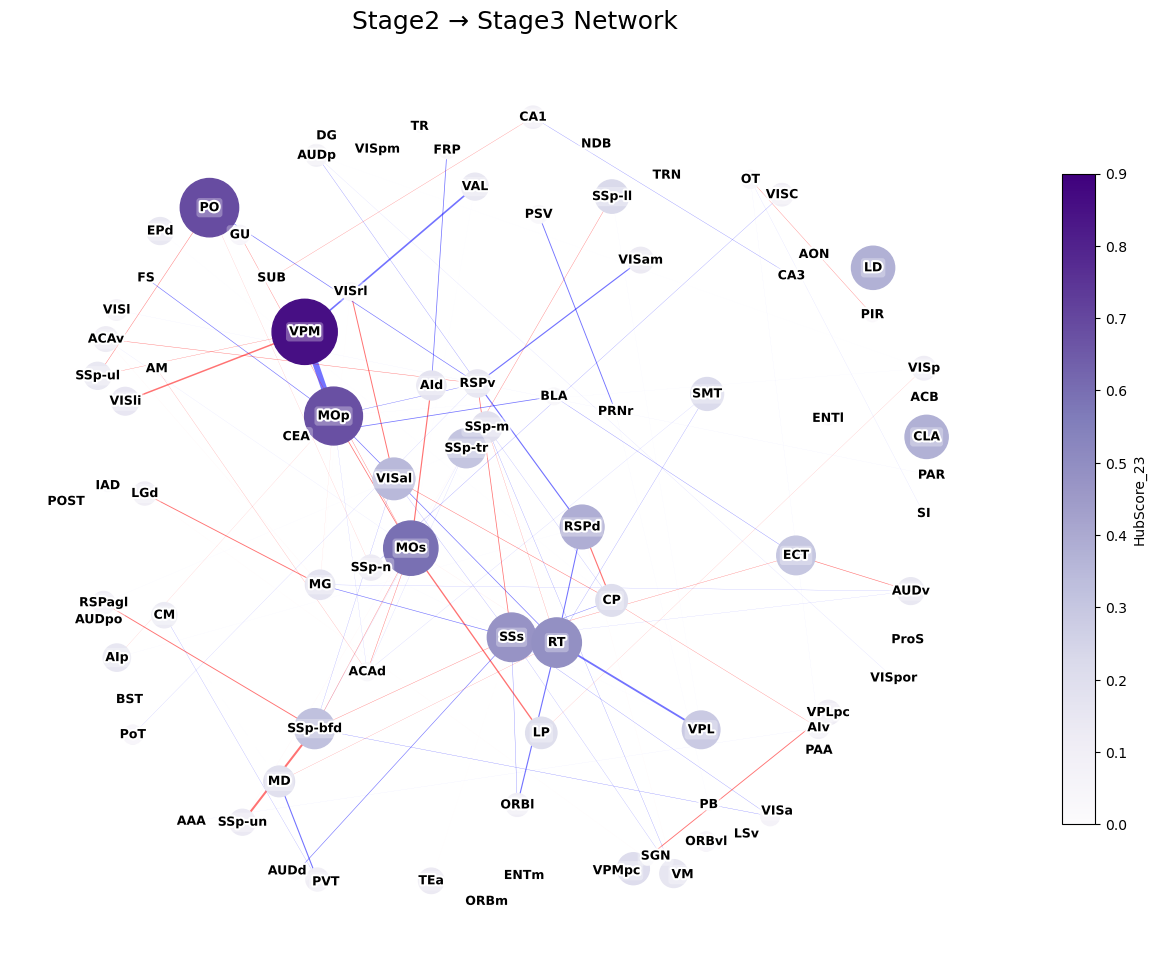

In [145]:
plot_explainable_network(
    D23, L2, df_hub, "HubScore_23",
    top_k=120,
    title="Stage2 → Stage3 Network",
    savepdf="./result/fig/network_stage23.png"
)